# Exercise 4 - Flipkart Reviews Analysis

Dataset: Flipkart Product Customer Reviews Dataset (Kaggle)
https://www.kaggle.com/datasets/niraliivaghani/flipkart-product-customer-reviews-dataset

## 1. Importing libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

## 2. Loading the dataset

In [ ]:
# change this to the name of the CSV file
file_name = "Dataset-SA.csv"

df = pd.read_csv(file_name)

print(df.shape)
df.head()

(205052, 6)


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


## 3. Checking the columns

In [ ]:
# making column names lowercase and without spaces 
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print(df.columns.tolist())

# column names used below
name_col = "product_name"
price_col = "product_price"
rate_col = "rate"
text_col = "summary"

# checking missing values
df.isnull().sum()

['product_name', 'product_price', 'rate', 'review', 'summary', 'sentiment']


product_name         0
product_price        0
rate                 0
review           24664
summary             11
sentiment            0
dtype: int64

## 4. Cleaning the price and rating columns

In [4]:
rows_before = df.shape[0]

# price: removing the rupee sign, commas and spaces, then converting to number
# (wrong values like product names in the price column become NaN)
df[price_col] = df[price_col].astype(str).str.replace(r"[₹,\s]", "", regex=True)
df[price_col] = pd.to_numeric(df[price_col], errors="coerce")

# rating: converting to number, wrong values become NaN
df[rate_col] = pd.to_numeric(df[rate_col], errors="coerce")

# dropping rows where product name, price or rating is missing
df = df.dropna(subset=[name_col, price_col, rate_col])

# rating should be between 1 and 5
df = df[(df[rate_col] >= 1) & (df[rate_col] <= 5)]

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", df.shape[0])
df[[name_col, price_col, rate_col]].head()

Rows before cleaning: 205052
Rows after cleaning: 205049


,product_name,product_price,rate
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,5.0
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,5.0
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,3.0
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,1.0
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,3.0


## 5. Mean rating and mean price for each product

In [5]:
# grouping by product name and taking the mean of rating and price
items = df.groupby(name_col)[[rate_col, price_col]].mean().reset_index()
items.columns = ["product_name", "mean_rating", "mean_price"]
items = items.round(2)

print("Number of products:", items.shape[0])
items.head(10)

Number of products: 958


,product_name,mean_rating,mean_price
0,1170BLBR Unique New Day Date Analog Watch F...,3.99,299.0
1,288SDTL TIMEWEAR Silver Pink Dial Stainless St...,4.41,339.0
2,38024PP25 Minimalists Analog Watch For Men,4.89,850.0
3,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.67,417.0
4,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.75,199.0
5,77085PP03 Volt Analog Watch For Men,4.71,699.0
6,7SEVEN Airtel DTH Remote Airtel Xstream Remote...,4.69,219.0
7,"ADONYX Combo of Knee,Palm, Elbow & Ankle Support",3.80,199.0
8,ADZOY Metal Lazy Stand Bracket for Neck Rest o...,3.52,284.0
9,AGAMI Green 2 Layer Lucky Bamboo plant with Bi...,4.46,279.0


## 6. Word cloud of the Summary column

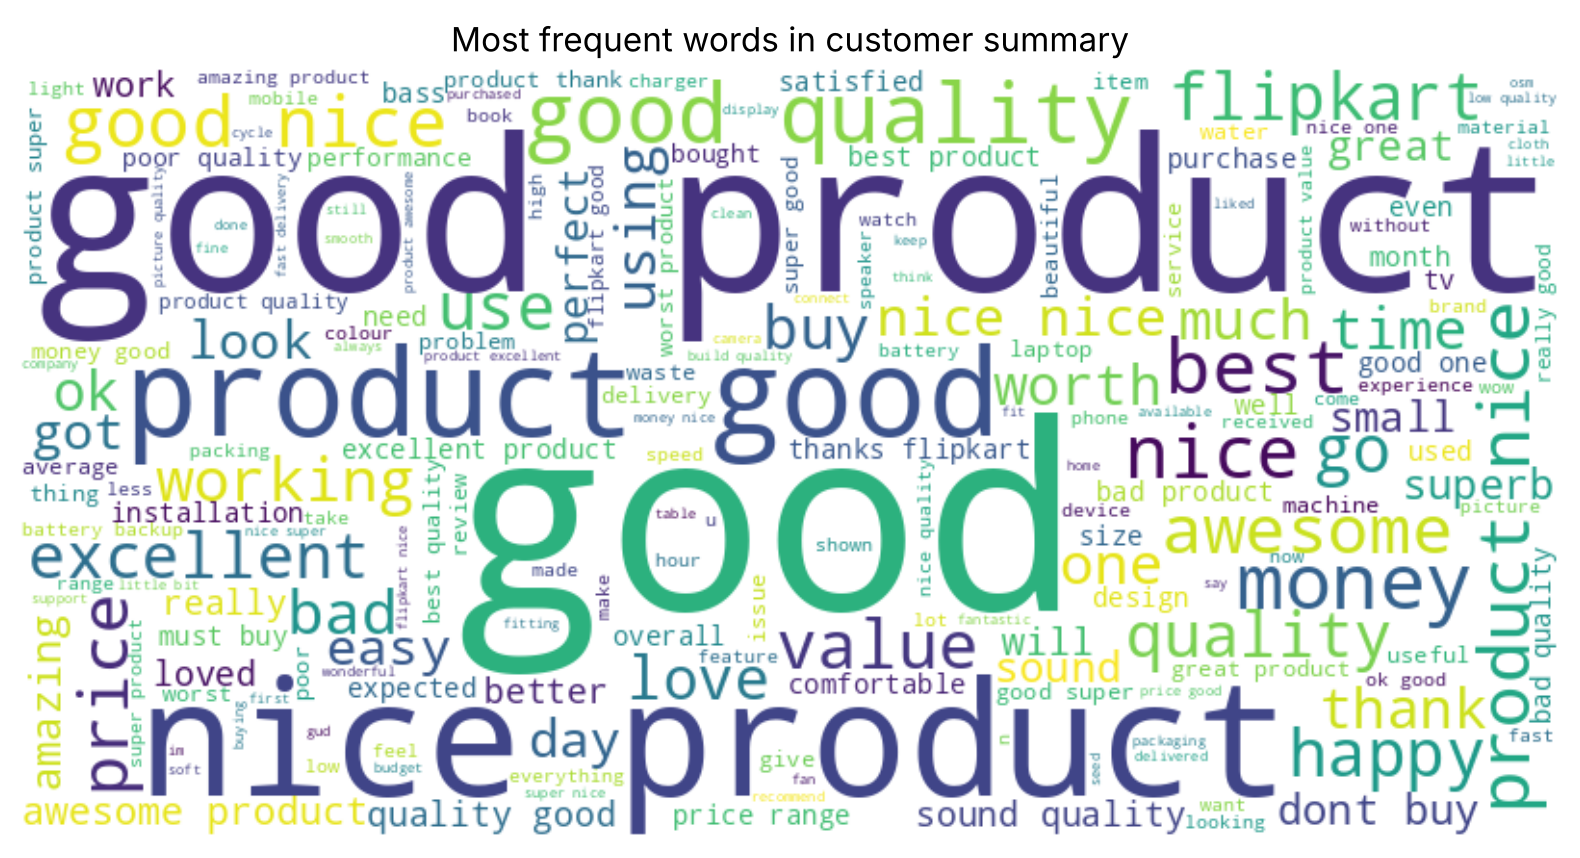

In [6]:
# joining all the summary texts into one big text
text = " ".join(df[text_col].dropna().astype(str))

# stopwords like 'the', 'is', 'and' are removed
wc = WordCloud(width=800, height=400, background_color="white", stopwords=STOPWORDS).generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Most frequent words in customer summary")
plt.show()

## Output notes
- The dataset has 205052 rows. Only 3 rows were removed in cleaning, because their price and rating columns had product names instead of numbers
- items has 958 products, each with its mean rating and mean price
- In the word cloud the biggest words are "good", "product", "nice" and "quality", so most customers wrote positive feedback
- Words like "bad", "worst" and "poor quality" also appear, but much smaller, so they are used less often